# Notebook 07 – Illustrative Prognose fuer 2027

**WICHTIGER HINWEIS:** Diese Prognose ist eine reine EXTRAPOLATION in die
echte Zukunft. Da fuer 2027 noch keine amtlichen MSS-Daten existieren,
kann diese Vorhersage NICHT validiert werden (keine echten Werte zum
Vergleich verfuegbar). Sie dient ausschliesslich als illustrative
Anwendung der trainierten Modelle und sollte in der Arbeit klar als
unvalidierte Zusatzanalyse gekennzeichnet werden (siehe Kapitel 6.2/7.3
der Masterarbeit).

**Voraussetzung:** Notebook 02 (mit der Erweiterung zur Sicherung des
juengsten Jahres) und Notebook 03/04 (trainierte Modelle) muessen zuvor
durchgelaufen sein.

In [2]:
# ═══════════════════════════════════════════════════════════════
# ZELLE 1: Imports & Daten laden
# ═══════════════════════════════════════════════════════════════

import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import geopandas as gpd
import pickle
import os
import warnings
warnings.filterwarnings('ignore')

from pytorch_forecasting import TemporalFusionTransformer, TimeSeriesDataSet

device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
print(f'Device: {device}')

df_full_raw = pd.read_csv('../data/final/df_full.csv')
df_full_raw['plr_id'] = df_full_raw['plr_id'].astype(str).str.zfill(8)

df_inferenz = pd.read_csv('../data/final/df_inferenz_2025.csv')
df_inferenz['plr_id'] = df_inferenz['plr_id'].astype(str).str.zfill(8)

with open('../models/meta.pkl', 'rb') as f:
    meta = pickle.load(f)
SEQ_LEN = meta.get('seq_len', 3)
ALLE_JAHRE_META = sorted(int(y) for y in meta.get('jahre', []))

with open('../models/target.pkl', 'rb') as f:
    TARGET = pickle.load(f)

print(f'SEQ_LEN: {SEQ_LEN}')
print(f'Anker-Jahre (Training): {ALLE_JAHRE_META}')

# Encoder-Jahre fuer die 2027-Prognose: die letzten SEQ_LEN Jahre
# (Anker-Jahre + das gesicherte juengste Jahr)
juengstes_jahr_inferenz = int(df_inferenz['year'].iloc[0])
alle_verfuegbaren_jahre = sorted(set(ALLE_JAHRE_META) | {juengstes_jahr_inferenz})
encoder_jahre_2027 = alle_verfuegbaren_jahre[-SEQ_LEN:]
ziel_jahr_bezeichnung = '2027 (illustrativ)'

print(f'\nEncoder-Jahre fuer 2027-Prognose: {encoder_jahre_2027}')
print(f'Vorhergesagtes Zieljahr: {ziel_jahr_bezeichnung}')

Device: mps
SEQ_LEN: 3
Anker-Jahre (Training): [2013, 2015, 2017, 2019, 2021, 2023]

Encoder-Jahre fuer 2027-Prognose: [2021, 2023, 2025]
Vorhergesagtes Zieljahr: 2027 (illustrativ)


In [3]:
# ═══════════════════════════════════════════════════════════════
# ZELLE 2: Vollstaendige Encoder-Sequenzen zusammenstellen
# ═══════════════════════════════════════════════════════════════

with open('../models/feature_cols.pkl', 'rb') as f:
    FEATURE_COLS = pickle.load(f)

df_alle_jahre = pd.concat([df_full_raw, df_inferenz], ignore_index=True)
df_alle_jahre = df_alle_jahre.drop_duplicates(subset=['plr_id', 'year'])
df_alle_jahre = df_alle_jahre.sort_values(['plr_id', 'year']).reset_index(drop=True)

# Nur PLR mit ALLEN drei Encoder-Jahren vollstaendig verwenden
jahre_pro_plr = df_alle_jahre.groupby('plr_id')['year'].apply(lambda s: set(int(y) for y in s))
vollstaendige_plr_2027 = jahre_pro_plr[
    jahre_pro_plr.apply(lambda s: set(encoder_jahre_2027).issubset(s))
].index

print(f'PLR mit vollstaendigen Encoder-Jahren {encoder_jahre_2027}: '
      f'{len(vollstaendige_plr_2027)} von {df_alle_jahre["plr_id"].nunique()}')

df_2027 = df_alle_jahre[
    (df_alle_jahre['plr_id'].isin(vollstaendige_plr_2027)) &
    (df_alle_jahre['year'].isin(encoder_jahre_2027))
].copy()

if len(vollstaendige_plr_2027) == 0:
    raise RuntimeError(
        'Keine PLR mit vollstaendigen Encoder-Jahren gefunden! '
        'Notebook 02 (Sicherung des juengsten Jahres) pruefen.'
    )

PLR mit vollstaendigen Encoder-Jahren [2021, 2023, 2025]: 539 von 541


In [4]:
# ═══════════════════════════════════════════════════════════════
# ZELLE 3: LSTM-Prognose fuer 2027
# ═══════════════════════════════════════════════════════════════

class BerlinLSTM(nn.Module):
    def __init__(self, input_size, hidden_size=32, num_layers=2):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers,
                            dropout=0.2, batch_first=True)
        self.fc = nn.Sequential(
            nn.Linear(hidden_size, 16), nn.ReLU(),
            nn.Dropout(0.2), nn.Linear(16, 1)
        )
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])


with open('../models/lstm_feature_cols_common.pkl', 'rb') as f:
    FEATURE_COLS_LSTM = pickle.load(f)
print(f'LSTM Features: {FEATURE_COLS_LSTM}')

lstm = BerlinLSTM(input_size=len(FEATURE_COLS_LSTM)).to(device)
lstm.load_state_dict(torch.load('../models/lstm_finetuned.pt', map_location=device))
lstm.eval()

lstm_ergebnisse = []
for plr_id, group in df_2027.groupby('plr_id'):
    group = group.sort_values('year')
    if len(group) != SEQ_LEN:
        continue
    X = group[FEATURE_COLS_LSTM].values.astype(np.float32)
    X_tensor = torch.FloatTensor(X).unsqueeze(0).to(device)  # (1, SEQ_LEN, n_features)
    with torch.no_grad():
        pred = lstm(X_tensor).cpu().numpy().flatten()[0]
    letzter_bekannter_wert = group['status_index'].iloc[-1]
    lstm_ergebnisse.append({
        'plr_id': plr_id,
        'status_2025_bekannt': letzter_bekannter_wert,
        'status_2027_lstm': pred,
        'veraenderung_lstm': pred - letzter_bekannter_wert,
    })

df_lstm_2027 = pd.DataFrame(lstm_ergebnisse)
print(f'\n✅ LSTM 2027-Prognose fuer {len(df_lstm_2027)} PLR berechnet')
print(df_lstm_2027.describe().round(3))

LSTM Features: ['arbeitslosigkeit', 'sgb2_quote', 'kinderarmut', 'dist_zentrum', 'status_lag']

✅ LSTM 2027-Prognose fuer 539 PLR berechnet
       status_2025_bekannt  status_2027_lstm  veraenderung_lstm
count              539.000           539.000            539.000
mean                 0.277             0.115             -0.162
std                  0.746             0.666              0.292
min                 -1.890            -1.626             -1.859
25%                 -0.224            -0.442             -0.318
50%                  0.434             0.258             -0.170
75%                  0.865             0.683             -0.012
max                  1.554             1.121              1.072


In [5]:
# ═══════════════════════════════════════════════════════════════
# ZELLE 4: TFT-Prognose fuer 2027
# ═══════════════════════════════════════════════════════════════
# TFT (pytorch-forecasting) benoetigt strukturell eine Zeile fuer den
# zu prognostizierenden Zeitpunkt. Da 2027 real nicht existiert, wird
# eine Platzhalter-Zeile ergaenzt (Features = Wiederholung des letzten
# bekannten Zeitpunkts, target = Platzhalter). Diese Platzhalterwerte
# dienen NUR der technischen Konstruktion des Datensatzes - sie fliessen
# NICHT als Information in die Vorhersage ein, da TFT im 'predict'-Modus
# fuer den zu prognostizierenden Schritt ausschliesslich auf Basis der
# ENCODER-Vergangenheit (2021, 2023, 2025) vorhersagt.

with open('../models/tft_feature_cols_common.pkl', 'rb') as f:
    FEATURE_COLS_TFT = pickle.load(f)
print(f'TFT Features: {FEATURE_COLS_TFT}')

df_tft_2027 = df_2027.copy()
year_map_2027 = {y: i for i, y in enumerate(encoder_jahre_2027)}
df_tft_2027['time_idx'] = df_tft_2027['year'].map(year_map_2027)

# WICHTIG: 2025-Zeilen haben kein echtes status_next (kein Folgejahr
# bekannt). TimeSeriesDataSet verlangt aber einen FINITEN Wert in JEDER
# Zeile (strukturell, nicht inhaltlich genutzt). Platzhalter = eigener
# status_index-Wert der Zeile - beeinflusst die Vorhersage NICHT, da
# TARGET ohnehin nicht in time_varying_unknown_reals steht (Option B).
df_tft_2027[TARGET] = df_tft_2027[TARGET].fillna(df_tft_2027['status_index'])

# Platzhalter-Decoder-Zeile (naechster Zeitschritt) je PLR ergaenzen
platzhalter_zeilen = []
letztes_jahr_df = df_tft_2027[df_tft_2027['year'] == encoder_jahre_2027[-1]]
for _, row in letztes_jahr_df.iterrows():
    neue_zeile = row.copy()
    neue_zeile['time_idx'] = row['time_idx'] + 1
    neue_zeile[TARGET] = row['status_index']  # Platzhalter, wird nicht als Info genutzt
    platzhalter_zeilen.append(neue_zeile)

df_tft_2027_mit_platzhalter = pd.concat(
    [df_tft_2027, pd.DataFrame(platzhalter_zeilen)], ignore_index=True
)

prognose_ds = TimeSeriesDataSet(
    df_tft_2027_mit_platzhalter,
    time_idx='time_idx', target=TARGET, group_ids=['plr_id'],
    max_encoder_length=SEQ_LEN, max_prediction_length=1,
    time_varying_known_reals=['time_idx'],
    time_varying_unknown_reals=FEATURE_COLS_TFT,  # Option B: TARGET nicht enthalten
    static_reals=['dist_zentrum'],
    target_normalizer=None, add_relative_time_idx=True,
    allow_missing_timesteps=True, predict_mode=True,
)
prognose_dl = prognose_ds.to_dataloader(train=False, batch_size=64, num_workers=0)

with open('../models/tft_checkpoint_path.pkl', 'rb') as f:
    tft_ckpt_path = pickle.load(f)
best_tft = TemporalFusionTransformer.load_from_checkpoint(tft_ckpt_path)

tft_preds_2027 = best_tft.predict(
    prognose_dl, trainer_kwargs=dict(accelerator='mps')
).numpy().flatten()

# PLR-Reihenfolge aus dem Dataset extrahieren
plr_reihenfolge = df_tft_2027_mit_platzhalter[
    df_tft_2027_mit_platzhalter['plr_id'].isin(vollstaendige_plr_2027)
]['plr_id'].unique()

df_tft_ergebnis = pd.DataFrame({
    'plr_id': plr_reihenfolge[:len(tft_preds_2027)],
    'status_2027_tft': tft_preds_2027,
})

print(f'✅ TFT 2027-Prognose fuer {len(df_tft_ergebnis)} PLR berechnet')
print(df_tft_ergebnis.describe().round(3))

TFT Features: ['arbeitslosigkeit', 'sgb2_quote', 'kinderarmut', 'dist_zentrum', 'status_lag']


GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.


✅ TFT 2027-Prognose fuer 539 PLR berechnet
       status_2027_tft
count          539.000
mean             0.275
std              0.689
min             -1.927
25%             -0.236
50%              0.432
75%              0.822
max              1.416


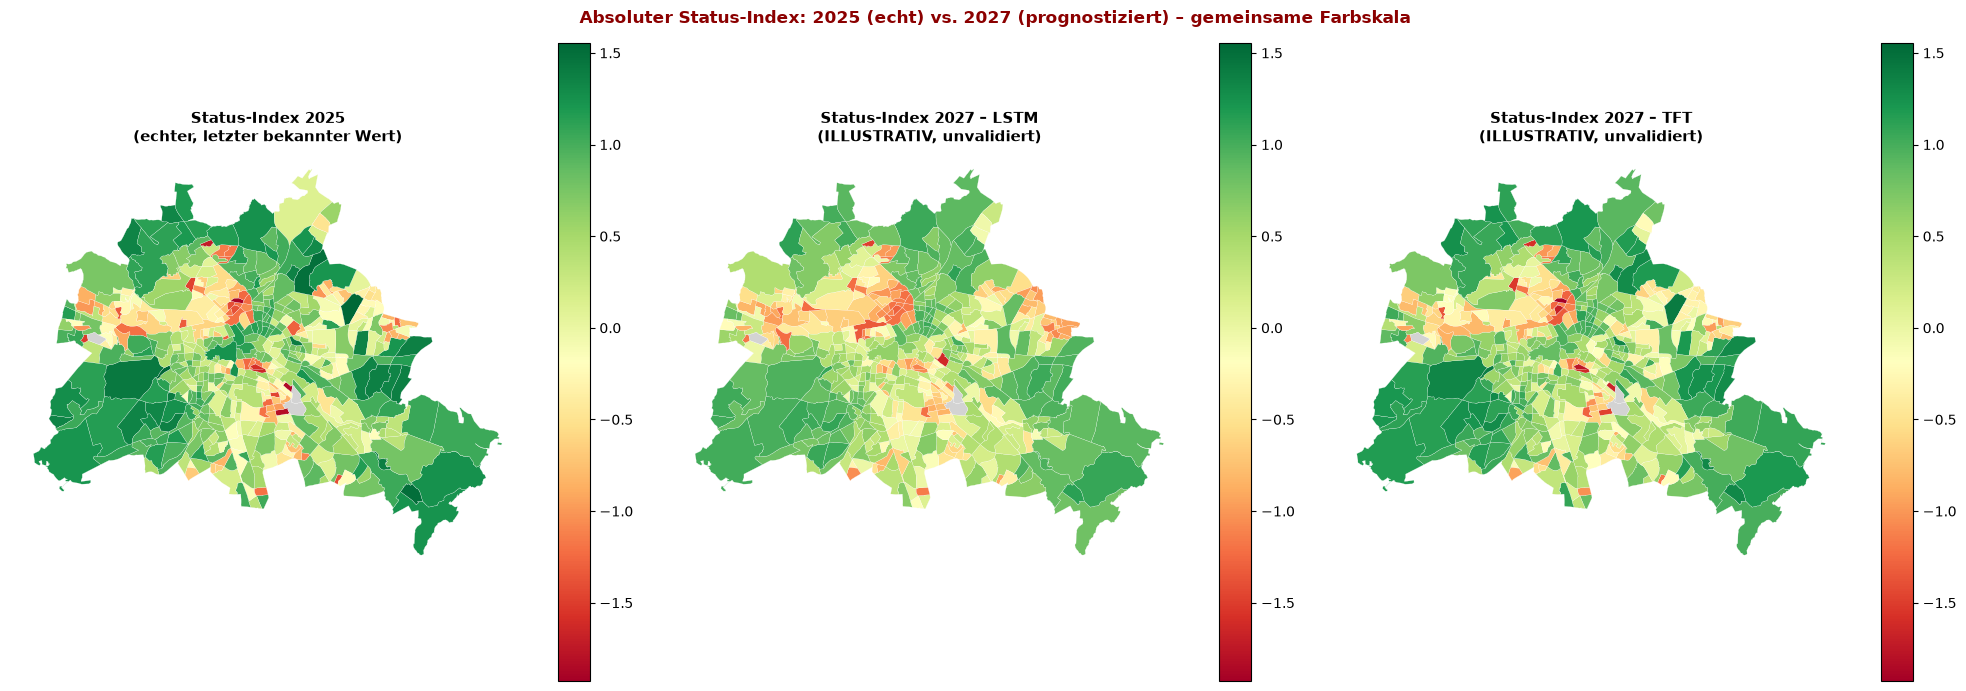

🏆 Top 5 hoechster prognostizierter Status-Index 2027 (TFT, illustrativ):
  plr_id  status_2025_bekannt  status_2027_tft
10100205             1.554041         1.416461
04400725             1.554023         1.391631
04200207             1.421182         1.335311
03601453             1.398358         1.331414
09401330             1.381164         1.310462

⚠️ Top 5 niedrigster prognostizierter Status-Index 2027 (TFT, illustrativ):
  plr_id  status_2025_bekannt  status_2027_tft
01300730            -1.890323        -1.927003
02100105            -1.584146        -1.752260
01401044            -1.388711        -1.684498
08100419            -1.832829        -1.667931
02100106            -1.652857        -1.622379

✅ Absolute Status-Index-Karten 2027 gespeichert (results/07_status_absolut_2027.png)


In [6]:
# ═══════════════════════════════════════════════════════════════
# ZELLE 5: Absoluter Status-Index 2027 (nicht nur Veraenderung)
# ═══════════════════════════════════════════════════════════════
# Zusaetzlich zur Veraenderungskarte (Zelle 6) wird hier der
# tatsaechlich prognostizierte, ABSOLUTE Status-Index-Wert fuer 2027
# selbst dargestellt - fuer beide Modelle im direkten Vergleich.

df_2027_final = df_lstm_2027.merge(df_tft_ergebnis, on='plr_id', how='inner')
df_2027_final['veraenderung_tft'] = (
    df_2027_final['status_2027_tft'] - df_2027_final['status_2025_bekannt']
)

gdf_polygone = gpd.read_file('../data/final/plr_polygone.gpkg')
gdf_polygone['plr_id'] = gdf_polygone['plr_id'].astype(str).str.zfill(8)
gdf_2027_absolut = gdf_polygone.merge(df_2027_final, on='plr_id', how='left')

# Gemeinsame Farbskala fuer echten 2025-Wert + beide 2027-Prognosen,
# damit die Karten visuell fair vergleichbar sind
alle_werte = pd.concat([
    df_2027_final['status_2025_bekannt'],
    df_2027_final['status_2027_lstm'],
    df_2027_final['status_2027_tft'],
])
vmin_abs, vmax_abs = alle_werte.min(), alle_werte.max()

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

gdf_2027_absolut.plot(column='status_2025_bekannt', cmap='RdYlGn',
                       vmin=vmin_abs, vmax=vmax_abs, legend=True,
                       edgecolor='white', linewidth=0.15,
                       missing_kwds={'color': 'lightgrey'}, ax=axes[0])
axes[0].set_title('Status-Index 2025\n(echter, letzter bekannter Wert)',
                   fontsize=11, fontweight='bold')
axes[0].set_axis_off()

gdf_2027_absolut.plot(column='status_2027_lstm', cmap='RdYlGn',
                       vmin=vmin_abs, vmax=vmax_abs, legend=True,
                       edgecolor='white', linewidth=0.15,
                       missing_kwds={'color': 'lightgrey'}, ax=axes[1])
axes[1].set_title('Status-Index 2027 – LSTM\n(ILLUSTRATIV, unvalidiert)',
                   fontsize=11, fontweight='bold')
axes[1].set_axis_off()

gdf_2027_absolut.plot(column='status_2027_tft', cmap='RdYlGn',
                       vmin=vmin_abs, vmax=vmax_abs, legend=True,
                       edgecolor='white', linewidth=0.15,
                       missing_kwds={'color': 'lightgrey'}, ax=axes[2])
axes[2].set_title('Status-Index 2027 – TFT\n(ILLUSTRATIV, unvalidiert)',
                   fontsize=11, fontweight='bold')
axes[2].set_axis_off()

plt.suptitle('Absoluter Status-Index: 2025 (echt) vs. 2027 (prognostiziert) – '
              'gemeinsame Farbskala',
             fontsize=12, fontweight='bold', color='darkred')
plt.tight_layout()
plt.savefig('../results/07_status_absolut_2027.png', dpi=150, bbox_inches='tight')
plt.show()

# Ranking: hoechste/niedrigste absolute Werte 2027 (TFT)
print('🏆 Top 5 hoechster prognostizierter Status-Index 2027 (TFT, illustrativ):')
print(df_2027_final.nlargest(5, 'status_2027_tft')[
    ['plr_id', 'status_2025_bekannt', 'status_2027_tft']
].to_string(index=False))

print('\n⚠️ Top 5 niedrigster prognostizierter Status-Index 2027 (TFT, illustrativ):')
print(df_2027_final.nsmallest(5, 'status_2027_tft')[
    ['plr_id', 'status_2025_bekannt', 'status_2027_tft']
].to_string(index=False))

print('\n✅ Absolute Status-Index-Karten 2027 gespeichert '
      '(results/07_status_absolut_2027.png)')

✅ Gemeinsame Prognose (LSTM + TFT): 539 PLR

📊 Vergleich LSTM vs. TFT (Mittelwerte):
status_2025_bekannt    0.2771
status_2027_lstm       0.1148
status_2027_tft        0.2747
dtype: float64

📈 Top 5 prognostizierte Aufwertung (TFT, illustrativ):
  plr_id  status_2025_bekannt  status_2027_tft  veraenderung_tft
11300723            -0.569941         0.250295          0.820236
03601450            -1.294952        -0.500075          0.794877
03100101             0.121970         0.912611          0.790642
01200627            -1.312958        -0.728431          0.584527
07100205            -0.942576        -0.417901          0.524675

📉 Top 5 prognostizierte Abwertung (TFT, illustrativ):
  plr_id  status_2025_bekannt  status_2027_tft  veraenderung_tft
02400625             0.233210        -0.579006         -0.812217
01400941            -0.038479        -0.503803         -0.465324
01100102             1.228208         0.854028         -0.374180
01401047            -0.593985        -0.965509   

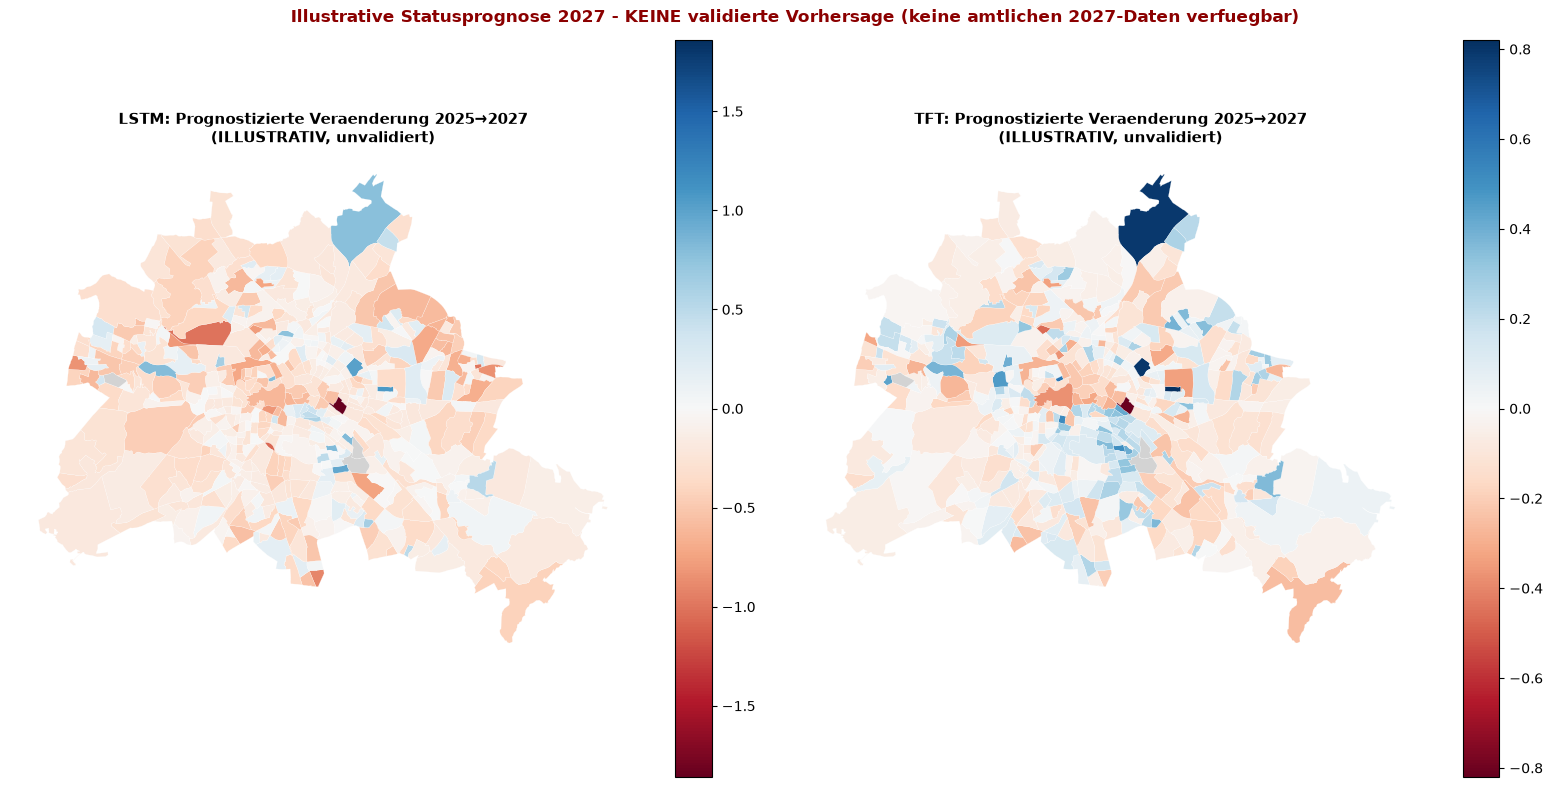


⚠️  WICHTIGER HINWEIS:
Diese 2027-Prognose ist NICHT validiert (keine echten
2027-Daten verfuegbar). Sie sollte in der Arbeit als
illustrative Zusatzanalyse gekennzeichnet werden, NICHT
als eigenstaendiges, belastbares Ergebnis (vgl. Kapitel
6.2 / 7.3 zur methodischen Einordnung von Prognosehorizonten
jenseits des validierten Testzeitraums).


In [7]:
# ═══════════════════════════════════════════════════════════════
# ZELLE 6: Veraenderungskarten (Delta 2025->2027) + Zusammenfassung
# ═══════════════════════════════════════════════════════════════

df_2027_final = df_lstm_2027.merge(df_tft_ergebnis, on='plr_id', how='inner')
df_2027_final['veraenderung_tft'] = (
    df_2027_final['status_2027_tft'] - df_2027_final['status_2025_bekannt']
)

print(f'✅ Gemeinsame Prognose (LSTM + TFT): {len(df_2027_final)} PLR')
print('\n📊 Vergleich LSTM vs. TFT (Mittelwerte):')
print(df_2027_final[['status_2025_bekannt', 'status_2027_lstm', 'status_2027_tft']]
      .mean().round(4))

# Top 5 staerkste prognostizierte Auf-/Abwertung (TFT, da methodisch praeziseres Modell)
print('\n📈 Top 5 prognostizierte Aufwertung (TFT, illustrativ):')
print(df_2027_final.nlargest(5, 'veraenderung_tft')[
    ['plr_id', 'status_2025_bekannt', 'status_2027_tft', 'veraenderung_tft']
].to_string(index=False))

print('\n📉 Top 5 prognostizierte Abwertung (TFT, illustrativ):')
print(df_2027_final.nsmallest(5, 'veraenderung_tft')[
    ['plr_id', 'status_2025_bekannt', 'status_2027_tft', 'veraenderung_tft']
].to_string(index=False))

# Kartographische Darstellung
gdf_polygone = gpd.read_file('../data/final/plr_polygone.gpkg')
gdf_polygone['plr_id'] = gdf_polygone['plr_id'].astype(str).str.zfill(8)

gdf_2027 = gdf_polygone.merge(df_2027_final, on='plr_id', how='left')

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

vmax_lstm = df_2027_final['veraenderung_lstm'].abs().max()
gdf_2027.plot(column='veraenderung_lstm', cmap='RdBu', vmin=-vmax_lstm, vmax=vmax_lstm,
              legend=True, edgecolor='white', linewidth=0.15,
              missing_kwds={'color': 'lightgrey'}, ax=axes[0])
axes[0].set_title('LSTM: Prognostizierte Veraenderung 2025→2027\n(ILLUSTRATIV, unvalidiert)',
                   fontsize=11, fontweight='bold')
axes[0].set_axis_off()

vmax_tft = df_2027_final['veraenderung_tft'].abs().max()
gdf_2027.plot(column='veraenderung_tft', cmap='RdBu', vmin=-vmax_tft, vmax=vmax_tft,
              legend=True, edgecolor='white', linewidth=0.15,
              missing_kwds={'color': 'lightgrey'}, ax=axes[1])
axes[1].set_title('TFT: Prognostizierte Veraenderung 2025→2027\n(ILLUSTRATIV, unvalidiert)',
                   fontsize=11, fontweight='bold')
axes[1].set_axis_off()

plt.suptitle('Illustrative Statusprognose 2027 - KEINE validierte Vorhersage '
              '(keine amtlichen 2027-Daten verfuegbar)',
             fontsize=12, fontweight='bold', color='darkred')
plt.tight_layout()
plt.savefig('../results/07_prognose_2027.png', dpi=150, bbox_inches='tight')
plt.show()

df_2027_final.to_csv('../results/prognose_2027.csv', index=False)

print('\n' + '='*60)
print('⚠️  WICHTIGER HINWEIS:')
print('='*60)
print('Diese 2027-Prognose ist NICHT validiert (keine echten')
print('2027-Daten verfuegbar). Sie sollte in der Arbeit als')
print('illustrative Zusatzanalyse gekennzeichnet werden, NICHT')
print('als eigenstaendiges, belastbares Ergebnis (vgl. Kapitel')
print('6.2 / 7.3 zur methodischen Einordnung von Prognosehorizonten')
print('jenseits des validierten Testzeitraums).')